In [2]:
import pandas as pd

# Load both files
fake_df = pd.read_csv("Fake.csv")
real_df = pd.read_csv("True.csv")

# Add labels before merging
fake_df["label"] = 0   # 0 = Fake
real_df["label"] = 1   # 1 = Real

# Combine into one dataframe
df = pd.concat([fake_df, real_df], ignore_index=True)

# Combine title + text into a single column (more signal for the model)
df["content"] = df["title"] + " " + df["text"]

# Shuffle the rows (important — the raw files are ordered by class!)
df = df.sample(frac=1, random_state=42).reset_index(drop=True)

print(df.shape)
print(df["label"].value_counts())

(44898, 6)
label
0    23481
1    21417
Name: count, dtype: int64


In [3]:
import pandas as pd

# Load both files
fake_df = pd.read_csv("Fake.csv")
real_df = pd.read_csv("True.csv")

# Add labels before merging
fake_df["label"] = 0   # 0 = Fake
real_df["label"] = 1   # 1 = Real

# Combine into one dataframe
df = pd.concat([fake_df, real_df], ignore_index=True)

# Combine title + text into a single column (more signal for the model)
df["content"] = df["title"] + " " + df["text"]

# Shuffle the rows (important — the raw files are ordered by class!)
df = df.sample(frac=1, random_state=42).reset_index(drop=True)

print(df.shape)
print(df["label"].value_counts())

(44898, 6)
label
0    23481
1    21417
Name: count, dtype: int64


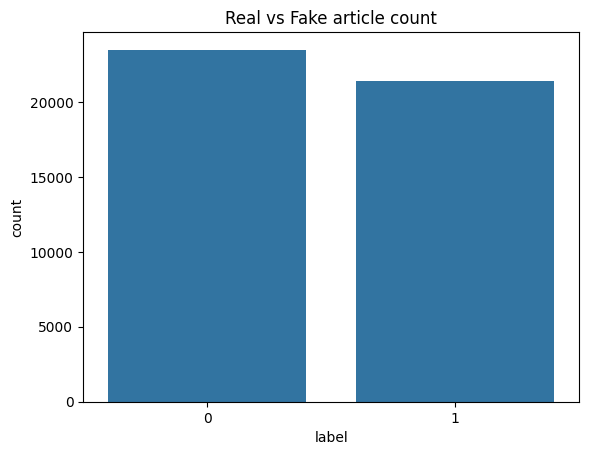

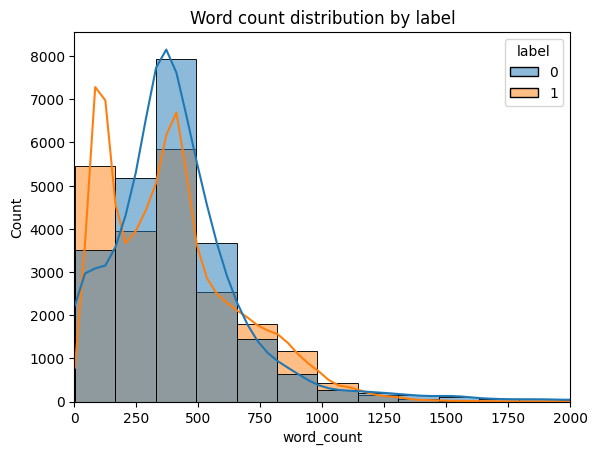

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Class balance — is it roughly 50/50?
sns.countplot(x="label", data=df)
plt.title("Real vs Fake article count")
plt.show()

# 2. Article length distribution — do fake articles tend to be shorter/longer?
df["word_count"] = df["content"].apply(lambda x: len(str(x).split()))
sns.histplot(data=df, x="word_count", hue="label", bins=50, kde=True)
plt.title("Word count distribution by label")
plt.xlim(0, 2000)
plt.show()

# 3. Most common words per class (after basic cleaning — see 1.3 first, then revisit this)

In [6]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

nltk.download('stopwords')
nltk.download('wordnet')

stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    text = str(text).lower()                          # lowercase
    text = re.sub(r'https?://\S+|www\.\S+', '', text) # remove URLs
    text = re.sub(r'<.*?>', '', text)                 # remove HTML tags
    text = re.sub(r'[^a-z\s]', '', text)               # remove punctuation/numbers
    tokens = text.split()                              # tokenize (simple whitespace split)
    tokens = [lemmatizer.lemmatize(word) for word in tokens if word not in stop_words]
    return " ".join(tokens)

df["clean_content"] = df["content"].apply(clean_text)

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\ashus\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\ashus\AppData\Roaming\nltk_data...


In [9]:
from sklearn.model_selection import train_test_split

X = df["clean_content"]
y = df["label"]

# First split: 70% train, 30% temp
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

# Second split: divide the 30% into 15% validation, 15% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

print(f"Train: {len(X_train)}, Val: {len(X_val)}, Test: {len(X_test)}")

Train: 31428, Val: 6735, Test: 6735


In [10]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(
    max_features=5000,     # cap vocabulary size — keeps things fast and manageable
    ngram_range=(1, 2)     # include both single words and 2-word phrases
)

# Fit ONLY on training data, then transform all three sets
X_train_tfidf = vectorizer.fit_transform(X_train)
X_val_tfidf = vectorizer.transform(X_val)
X_test_tfidf = vectorizer.transform(X_test)

In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Naive Bayes": MultinomialNB(),
    "SVM": LinearSVC()
}

results = {}

for name, model in models.items():
    model.fit(X_train_tfidf, y_train)
    preds = model.predict(X_val_tfidf)   # evaluate on VALIDATION, not test, at this stage

    results[name] = {
        "accuracy": accuracy_score(y_val, preds),
        "precision": precision_score(y_val, preds),
        "recall": recall_score(y_val, preds),
        "f1": f1_score(y_val, preds)
    }

results_df = pd.DataFrame(results).T
print(results_df)

                     accuracy  precision    recall        f1
Logistic Regression  0.989013   0.983965  0.993153  0.988538
Naive Bayes          0.943875   0.939535  0.943044  0.941286
SVM                  0.996140   0.996263  0.995643  0.995953


Final Test Accuracy: 0.9961395694135116
Final Test F1-score: 0.9959501557632399


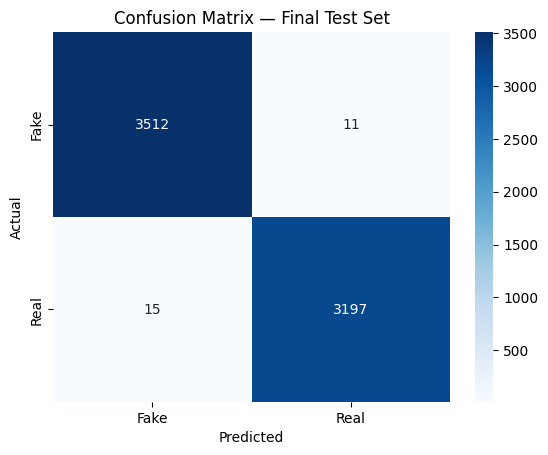

In [12]:
# Say SVM wins based on validation results
best_model = models["SVM"]

# NOW, and only now, touch the test set
final_preds = best_model.predict(X_test_tfidf)

print("Final Test Accuracy:", accuracy_score(y_test, final_preds))
print("Final Test F1-score:", f1_score(y_test, final_preds))

cm = confusion_matrix(y_test, final_preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Fake', 'Real'], yticklabels=['Fake', 'Real'])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix — Final Test Set")
plt.show()

In [15]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

# Tokenize into integer sequences (different from TF-IDF — LSTM needs word ORDER preserved)
tokenizer = Tokenizer(num_words=10000)
tokenizer.fit_on_texts(X_train)

X_train_seq = pad_sequences(tokenizer.texts_to_sequences(X_train), maxlen=300)
X_val_seq = pad_sequences(tokenizer.texts_to_sequences(X_val), maxlen=300)
X_test_seq = pad_sequences(tokenizer.texts_to_sequences(X_test), maxlen=300)

model = Sequential([
    Embedding(input_dim=10000, output_dim=128, input_length=300),
    LSTM(64, dropout=0.2, recurrent_dropout=0.2),
    Dense(32, activation='relu'),
    Dropout(0.3),
    Dense(1, activation='sigmoid')
])

model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])
model.fit(X_train_seq, y_train, validation_data=(X_val_seq, y_val), epochs=5, batch_size=64)

Epoch 1/5
492/492 ━━━━━━━━━━━━━━━━━━━━ 127s 254ms/step - accuracy: 0.9454 - loss: 0.1569 - val_accuracy: 0.9727 - val_loss: 0.0898
Epoch 2/5
 99/492 ━━━━━━━━━━━━━━━━━━━━ 1:35 243ms/step - accuracy: 0.9714 - loss: 0.0914

KeyboardInterrupt: 

In [16]:
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import classification_report, confusion_matrix
import joblib

# Stop when validation loss stops improving, and keep the best weights
early_stop = EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)

history = model.fit(
    X_train_seq, y_train,
    validation_data=(X_val_seq, y_val),
    epochs=5, batch_size=64,
    callbacks=[early_stop],
    verbose=2
)

# Final evaluation: touch the test set ONLY now
probs = model.predict(X_test_seq).ravel()
preds = (probs > 0.5).astype(int)
print(classification_report(y_test, preds, target_names=['Fake', 'Real']))
print(confusion_matrix(y_test, preds))

# Save for the web app
model.save("lstm_model.keras")
joblib.dump(tokenizer, "lstm_tokenizer.pkl")

Epoch 1/5
492/492 - 132s - 268ms/step - accuracy: 0.9832 - loss: 0.0572 - val_accuracy: 0.9826 - val_loss: 0.0640
Epoch 2/5
492/492 - 121s - 245ms/step - accuracy: 0.9896 - loss: 0.0351 - val_accuracy: 0.9857 - val_loss: 0.0511
Epoch 3/5
492/492 - 122s - 248ms/step - accuracy: 0.9903 - loss: 0.0303 - val_accuracy: 0.9874 - val_loss: 0.0406
Epoch 4/5
492/492 - 117s - 237ms/step - accuracy: 0.9951 - loss: 0.0157 - val_accuracy: 0.9877 - val_loss: 0.0453
Epoch 5/5
492/492 - 117s - 239ms/step - accuracy: 0.9979 - loss: 0.0079 - val_accuracy: 0.9917 - val_loss: 0.0329
211/211 ━━━━━━━━━━━━━━━━━━━━ 7s 31ms/step
              precision    recall  f1-score   support

        Fake       0.99      0.99      0.99      3523
        Real       0.99      0.99      0.99      3212

    accuracy                           0.99      6735
   macro avg       0.99      0.99      0.99      6735
weighted avg       0.99      0.99      0.99      6735

[[3484   39]
 [  22 3190]]


['lstm_tokenizer.pkl']

In [17]:
import joblib

joblib.dump(best_model, "english_model.pkl")
joblib.dump(vectorizer, "tfidf_vectorizer.pkl")

# Later, in your web app:
# model = joblib.load("english_model.pkl")
# vectorizer = joblib.load("tfidf_vectorizer.pkl")

['tfidf_vectorizer.pkl']